# Machine Translation with a Transformer

English-to-French sequence-to-sequence translation using the local Transformer encoder-decoder and data pipeline.

In [1]:
import collections
import logging
import math
import sys
import time
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch import nn

PROJECT_ROOT = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.mt.data import DataLoaderConfig, MTData, MTDataInput
from src.transformer import (
    TransformerDecoder,
    TransformerDecoderInput,
    TransformerEncoder,
    TransformerEncoderInput,
)

## Prepare the corpus

`MTData` downloads the archive only when missing, normalizes punctuation, tokenizes sentence pairs, builds `Vocab` instances, pads sequences, and creates train/validation loaders.

In [2]:
DATA_URL = 'https://www.manythings.org/anki/fra-eng.zip'
MAX_STEPS = 20
BATCH_SIZE = 256
RANDOM_SEED = 42

torch.manual_seed(RANDOM_SEED)
mt_data = MTData(
    MTDataInput(
        DATA_URL,
        zip_data=True,
        max_steps=MAX_STEPS,
        data_dir=PROJECT_ROOT / 'notebooks' / 'data',
    )
)
mt_data.download_and_extract()
raw_text = mt_data.read_data('fra.txt')
source_tokens, target_tokens = mt_data.tokenize(mt_data.preprocess(raw_text))
train_loader, validation_loader = mt_data.build_dataloaders(
    source_tokens,
    target_tokens,
    DataLoaderConfig(80, 20, BATCH_SIZE),
)

print(f'{len(source_tokens):,} sentence pairs')
print(f'{len(mt_data.src_vocab):,} source tokens; {len(mt_data.tgt_vocab):,} target tokens')
source_tokens[:3], target_tokens[:3]

240,521 sentence pairs
11,228 source tokens; 19,213 target tokens


([['go', '.', '<eos>'], ['go', '.', '<eos>'], ['go', '.', '<eos>']],
 [['va', '!', '<eos>'],
  ['marche', '.', '<eos>'],
  ['en', 'route', '!', '<eos>']])

In [3]:
source, source_lengths, target, target_lengths = next(iter(train_loader))
print(source.shape, source_lengths.shape, target.shape, target_lengths.shape)
print(mt_data.src_vocab.to_tokens(source[0].tolist()))
print(mt_data.tgt_vocab.to_tokens(target[0].tolist()))

torch.Size([256, 20]) torch.Size([256]) torch.Size([256, 20]) torch.Size([256])
["i'd", 'like', 'to', 'confirm', 'our', 'reservations', '.', '<eos>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>']
['<bos>', "j'aimerais", 'confirmer', 'nos', 'réservations', '.', '<eos>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>']


## Transformer encoder-decoder

The encoder runs self-attention over the source tokens and masks source padding with `source_lengths`. Each decoder block runs causal self-attention over the target prefix, then encoder-decoder attention over the encoder outputs.

In [4]:
NUM_HIDDENS = 256
NUM_HIDDENS_FFN = 1024
NUM_HEADS = 4
NUM_BLOCKS = 2
DROPOUT = 0.1
LEARNING_RATE = 1e-3
GRAD_CLIP = 1.0
EPOCHS = 15
LOG_EVERY = 100  # Training batches between progress log lines.
DEVICE = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
MODEL_PATH = PROJECT_ROOT / 'translation_model.pt'

encoder = TransformerEncoder(
    TransformerEncoderInput(
        vocab_size=len(mt_data.src_vocab),
        num_hiddens=NUM_HIDDENS,
        num_hiddens_ffn=NUM_HIDDENS_FFN,
        num_heads=NUM_HEADS,
        num_blocks=NUM_BLOCKS,
        dropout=DROPOUT,
    )
).to(DEVICE)
decoder = TransformerDecoder(
    TransformerDecoderInput(
        vocab_size=len(mt_data.tgt_vocab),
        num_hiddens=NUM_HIDDENS,
        num_hiddens_ffn=NUM_HIDDENS_FFN,
        num_heads=NUM_HEADS,
        num_blocks=NUM_BLOCKS,
        dropout=DROPOUT,
    )
).to(DEVICE)
model = nn.ModuleList((encoder, decoder))

# The attention and FFN layers are LazyLinear, so one forward pass sets their
# input sizes. Run it before the optimizer collects the parameters.
with torch.no_grad():
    source, source_lengths, target, _ = (
        tensor.to(DEVICE) for tensor in next(iter(train_loader))
    )
    decoder(target, decoder.init_state(encoder(source, source_lengths), source_lengths))

optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
PAD_INDEX = mt_data.tgt_vocab['<pad>']
loss_function = nn.CrossEntropyLoss(ignore_index=PAD_INDEX, reduction='sum')
parameter_count = sum(parameter.numel() for parameter in model.parameters())

# Log to the notebook and to a new file per run.
LOG_PATH = PROJECT_ROOT / 'logs' / f'training_{datetime.now():%Y%m%d_%H%M%S}.log'
LOG_PATH.parent.mkdir(exist_ok=True)
logger = logging.getLogger('machine_translation')
logger.setLevel(logging.INFO)
logger.propagate = False
for handler in logger.handlers[:]:  # Re-running the cell must not duplicate log lines.
    logger.removeHandler(handler)
    handler.close()
for handler in (
    logging.StreamHandler(sys.stdout),
    logging.FileHandler(LOG_PATH, encoding='utf-8'),
):
    handler.setFormatter(logging.Formatter('%(asctime)s | %(message)s', datefmt='%H:%M:%S'))
    logger.addHandler(handler)

logger.info(f'log file: {LOG_PATH}')
logger.info(
    f'data: {len(train_loader.dataset):,} train / {len(validation_loader.dataset):,} validation pairs'
    f' | batch_size {BATCH_SIZE} | max_steps {MAX_STEPS}'
    f' | vocab {len(mt_data.src_vocab):,} en / {len(mt_data.tgt_vocab):,} fr'
)
logger.info(
    f'model: {parameter_count:,} parameters | hiddens {NUM_HIDDENS} | ffn {NUM_HIDDENS_FFN}'
    f' | heads {NUM_HEADS} | blocks {NUM_BLOCKS} | dropout {DROPOUT}'
)
logger.info(
    f'training: Adam lr {LEARNING_RATE} | grad_clip {GRAD_CLIP} | epochs {EPOCHS}'
    f' | device {DEVICE} | seed {RANDOM_SEED}'
)

08:11:39 | log file: /Users/ocdbytes/Desktop/ML/Transformers/logs/training_20261005_081139.log
08:11:39 | data: 192,416 train / 48,105 validation pairs | batch_size 256 | max_steps 20 | vocab 11,228 en / 19,213 fr
08:11:39 | model: 16,410,893 parameters | hiddens 256 | ffn 1024 | heads 4 | blocks 2 | dropout 0.1
08:11:39 | training: Adam lr 0.001 | grad_clip 1.0 | epochs 15 | device mps | seed 42


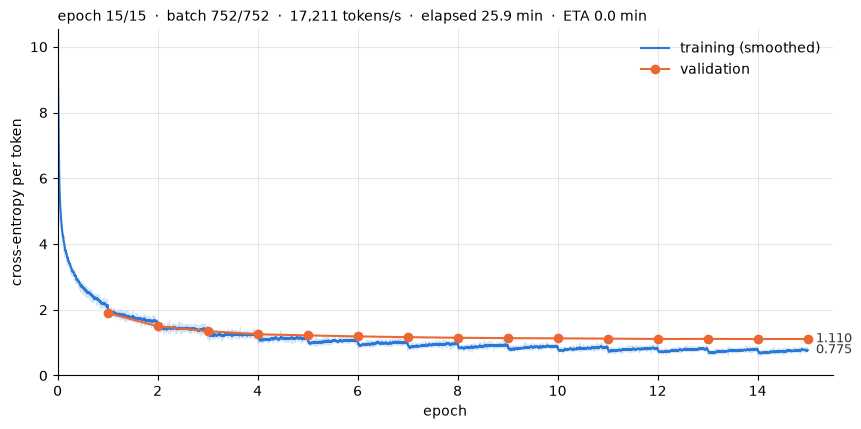

08:11:56 | training for 15 epochs of 752 batches
08:12:09 | epoch 1/15 | batch 100/752 | loss 4.9084 | ppl 135.42 | grad_norm 1.244 | 16,778 tok/s | elapsed 0.2m | eta 24.4m | mem 0.27GB
08:12:21 | epoch 1/15 | batch 200/752 | loss 3.5307 | ppl 34.15 | grad_norm 1.173 | 16,984 tok/s | elapsed 0.4m | eta 23.8m | mem 0.27GB
08:12:34 | epoch 1/15 | batch 300/752 | loss 3.0485 | ppl 21.08 | grad_norm 1.220 | 16,922 tok/s | elapsed 0.6m | eta 23.6m | mem 0.27GB
08:12:47 | epoch 1/15 | batch 400/752 | loss 2.7328 | ppl 15.38 | grad_norm 1.266 | 16,961 tok/s | elapsed 0.9m | eta 23.3m | mem 0.27GB
08:13:00 | epoch 1/15 | batch 500/752 | loss 2.5237 | ppl 12.47 | grad_norm 1.268 | 16,988 tok/s | elapsed 1.1m | eta 23.1m | mem 0.27GB
08:13:12 | epoch 1/15 | batch 600/752 | loss 2.3647 | ppl 10.64 | grad_norm 1.270 | 17,005 tok/s | elapsed 1.3m | eta 22.8m | mem 0.27GB
08:13:25 | epoch 1/15 | batch 700/752 | loss 2.2244 | ppl 9.25 | grad_norm 1.277 | 17,029 tok/s | elapsed 1.5m | eta 22.6m | mem

In [5]:
from IPython.display import display

TRAIN_COLOR, VALIDATION_COLOR = '#2a78d6', '#eb6834'


def elapsed_and_eta(started, epoch, batch_number, batches_per_epoch):
    """Returns seconds since `started` and the estimated seconds left in training."""
    done = (epoch - 1) * batches_per_epoch + batch_number
    elapsed = time.perf_counter() - started
    return elapsed, elapsed / done * (EPOCHS * batches_per_epoch - done)


def device_memory_gb():
    """Returns the memory held by tensors on DEVICE in GB, or None on the CPU."""
    if DEVICE.type == 'cuda':
        return torch.cuda.memory_allocated(DEVICE) / 1e9
    if DEVICE.type == 'mps':
        return torch.mps.current_allocated_memory() / 1e9
    return None


class LiveLossPlot:
    """Loss chart that redraws in place while the model trains.

    Args:
        batches_per_epoch: Training batches per epoch, used to place each batch
            on a fractional-epoch x axis.
        refresh_every: Redraw after this many batches. A redraw takes about
            0.1 s, so redrawing after every batch would slow training down.
        smoothing: Weight of the previous value in the moving average of the
            batch losses.
    """

    def __init__(self, batches_per_epoch, refresh_every=25, smoothing=0.9):
        self.batches_per_epoch = batches_per_epoch
        self.refresh_every = refresh_every
        self.smoothing = smoothing
        self.steps, self.batch_losses, self.smoothed = [], [], []
        self.validation = []
        self.started = time.perf_counter()
        self.fig, self.ax = plt.subplots(figsize=(10, 4.5))
        plt.close(self.fig)  # Shown only through the display handle, not again at cell end.
        self.handle = display(self.fig, display_id=True)

    def add_batch(self, epoch, batch_number, loss, tokens_per_second):
        previous = self.smoothed[-1] if self.smoothed else loss
        self.steps.append(epoch - 1 + batch_number / self.batches_per_epoch)
        self.batch_losses.append(loss)
        self.smoothed.append(self.smoothing * previous + (1 - self.smoothing) * loss)
        if batch_number % self.refresh_every == 0:
            self.draw(epoch, batch_number, tokens_per_second)

    def add_validation(self, epoch, loss, tokens_per_second):
        self.validation.append((epoch, loss))
        self.draw(epoch, self.batches_per_epoch, tokens_per_second)

    def draw(self, epoch, batch_number, tokens_per_second):
        ax = self.ax
        ax.clear()
        ax.plot(self.steps, self.batch_losses, color=TRAIN_COLOR, alpha=0.2, linewidth=0.75)
        ax.plot(
            self.steps, self.smoothed, color=TRAIN_COLOR, linewidth=1.5,
            label='training (smoothed)',
        )
        end_points = [(self.steps[-1], self.smoothed[-1])]
        if self.validation:
            epochs, losses = zip(*self.validation)
            ax.plot(
                epochs, losses, color=VALIDATION_COLOR, linewidth=1.5,
                marker='o', markersize=6, label='validation',
            )
            end_points.append(self.validation[-1])
        for x, y in end_points:
            ax.annotate(
                f'{y:.3f}', (x, y), xytext=(6, 0), textcoords='offset points',
                va='center', fontsize=9, color='#333333',
            )

        elapsed, remaining = elapsed_and_eta(
            self.started, epoch, batch_number, self.batches_per_epoch
        )
        ax.set_title(
            f'epoch {epoch}/{EPOCHS}  ·  batch {batch_number}/{self.batches_per_epoch}'
            f'  ·  {tokens_per_second:,.0f} tokens/s'
            f'  ·  elapsed {elapsed / 60:.1f} min  ·  ETA {remaining / 60:.1f} min',
            loc='left', fontsize=10,
        )
        ax.set_xlim(0, EPOCHS + 0.5)  # Leaves room for the end labels.
        ax.set_ylim(bottom=0)
        ax.set_xlabel('epoch')
        ax.set_ylabel('cross-entropy per token')
        ax.grid(alpha=0.3)
        ax.spines[['top', 'right']].set_visible(False)
        ax.legend(loc='upper right', frameon=False)
        self.handle.update(self.fig)

def batch_loss(batch):
    source, source_lengths, target, _ = (tensor.to(DEVICE) for tensor in batch)
    decoder_input, labels = target[:, :-1], target[:, 1:]
    encoded = encoder(source, source_lengths)
    state = decoder.init_state(encoded, source_lengths)
    logits, _ = decoder(decoder_input, state)
    token_count = (labels != PAD_INDEX).sum()
    loss = loss_function(logits.reshape(-1, logits.shape[-1]), labels.reshape(-1))
    return loss, token_count

history = []
best_validation, best_epoch = math.inf, 0
live_plot = LiveLossPlot(len(train_loader))
logger.info(f'training for {EPOCHS} epochs of {len(train_loader)} batches')
for epoch in range(1, EPOCHS + 1):
    started = time.perf_counter()
    model.train()
    train_loss_sum = train_tokens = 0
    interval_loss = interval_tokens = interval_grad_norm = interval_batches = 0
    for batch_number, batch in enumerate(train_loader, 1):
        optimizer.zero_grad(set_to_none=True)
        loss, token_count = batch_loss(batch)
        (loss / token_count.clamp_min(1)).backward()
        # clip_grad_norm_ returns the gradient norm measured before clipping.
        grad_norm = nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP).item()
        optimizer.step()
        loss_value, tokens = loss.item(), token_count.item()
        train_loss_sum += loss_value
        train_tokens += tokens
        tokens_per_second = train_tokens / (time.perf_counter() - started)
        live_plot.add_batch(
            epoch, batch_number, loss_value / max(tokens, 1), tokens_per_second
        )

        interval_loss += loss_value
        interval_tokens += tokens
        interval_grad_norm += grad_norm
        interval_batches += 1
        if batch_number % LOG_EVERY == 0 or batch_number == len(train_loader):
            interval_mean = interval_loss / max(interval_tokens, 1)
            elapsed, remaining = elapsed_and_eta(
                live_plot.started, epoch, batch_number, len(train_loader)
            )
            memory = device_memory_gb()
            logger.info(
                f'epoch {epoch}/{EPOCHS} | batch {batch_number}/{len(train_loader)}'
                f' | loss {interval_mean:.4f} | ppl {math.exp(interval_mean):.2f}'
                f' | grad_norm {interval_grad_norm / interval_batches:.3f}'
                f' | {tokens_per_second:,.0f} tok/s'
                f' | elapsed {elapsed / 60:.1f}m | eta {remaining / 60:.1f}m'
                + ('' if memory is None else f' | mem {memory:.2f}GB')
            )
            interval_loss = interval_tokens = interval_grad_norm = interval_batches = 0
    train_seconds = time.perf_counter() - started
    train_tokens_per_second = train_tokens / train_seconds

    model.eval()
    validation_loss_sum = validation_tokens = 0
    with torch.no_grad():
        for batch in validation_loader:
            loss, token_count = batch_loss(batch)
            validation_loss_sum += loss.item()
            validation_tokens += token_count.item()
    validation_seconds = time.perf_counter() - started - train_seconds

    losses = (
        train_loss_sum / train_tokens,
        validation_loss_sum / validation_tokens,
    )
    history.append(losses)
    live_plot.add_validation(epoch, losses[1], train_tokens_per_second)
    improved = losses[1] < best_validation
    if improved:
        best_validation, best_epoch = losses[1], epoch
    logger.info(
        f'epoch {epoch}/{EPOCHS} done | train loss {losses[0]:.4f} ppl {math.exp(losses[0]):.2f}'
        f' | val loss {losses[1]:.4f} ppl {math.exp(losses[1]):.2f}'
        f' | best val {best_validation:.4f} @ epoch {best_epoch}{" (new best)" if improved else ""}'
        f' | train {train_seconds:.0f}s, val {validation_seconds:.0f}s'
    )

logger.info(
    f'training finished in {(time.perf_counter() - live_plot.started) / 60:.1f}m'
    f' | best val loss {best_validation:.4f} @ epoch {best_epoch}'
)

In [6]:
torch.save(model.state_dict(), MODEL_PATH)
logger.info(f'saved model to {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1e6:.1f} MB)')

08:40:04 | saved model to /Users/ocdbytes/Desktop/ML/Transformers/translation_model.pt (65.7 MB)


## Beam-search translation and attention

In [7]:
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE, weights_only=True))
model.eval()

@torch.inference_mode()
def translate(
    sentence: str, max_steps: int = MAX_STEPS, beam_size: int = 4,
    length_penalty: float = 0.6,
):
    if not 1 <= beam_size <= len(mt_data.tgt_vocab) or length_penalty < 0:
        raise ValueError('beam_size must fit the vocabulary and length_penalty be non-negative')

    model.eval()
    tokens = mt_data.preprocess(sentence).strip().split() + ['<eos>']
    valid_length = min(len(tokens), max_steps)
    padded = tokens[:max_steps] + ['<pad>'] * max(0, max_steps - len(tokens))
    source = torch.tensor([mt_data.src_vocab[padded]], device=DEVICE)
    source_lengths = torch.tensor([valid_length], device=DEVICE)
    state = decoder.init_state(encoder(source, source_lengths), source_lengths)
    bos_index = mt_data.tgt_vocab['<bos>']
    eos_index = mt_data.tgt_vocab['<eos>']
    pad_index = mt_data.tgt_vocab['<pad>']
    beams = [([bos_index], 0.0, state)]

    def normalized_score(beam):
        generated_length = max(1, len(beam[0]) - 1)
        return beam[1] / (((5 + generated_length) / 6) ** length_penalty)

    for _ in range(max_steps):
        candidates = []
        for token_indices, score, beam_state in beams:
            if token_indices[-1] == eos_index:
                candidates.append((token_indices, score, beam_state))
                continue

            decoder_input = torch.tensor([[token_indices[-1]]], device=DEVICE)
            logits, next_state = decoder(decoder_input, beam_state)
            log_probabilities = torch.log_softmax(logits[0, -1], dim=-1)
            log_probabilities[[bos_index, pad_index]] = -torch.inf
            top_scores, top_indices = log_probabilities.topk(beam_size)

            for log_probability, next_index in zip(
                top_scores.cpu().tolist(), top_indices.cpu().tolist()
            ):
                candidates.append((
                    [*token_indices, next_index],
                    score + log_probability,
                    next_state,
                ))

        beams = sorted(candidates, key=normalized_score, reverse=True)[:beam_size]
        if all(beam[0][-1] == eos_index for beam in beams):
            break

    best_indices, _, _ = max(beams, key=normalized_score)
    output_tokens = []
    for index in best_indices[1:]:
        if index == eos_index:
            break
        output_tokens.append(mt_data.tgt_vocab.to_tokens(index))

    translation = ' '.join(output_tokens)
    for punctuation in ',.!?':
        translation = translation.replace(f' {punctuation}', punctuation)
    return translation, tokens[:valid_length], output_tokens

sentences = [
    "I am tired.",
    "I am happy.",
    "He is my friend.",
    "She went home.",
    "I like this book.",
    "Where is the station?",
    "I went to the market.",
    "My friend called me yesterday.",
    "I bought some fruit this morning.",
    "The weather is nice today.",
    "I want to walk in the park.",
    "We are going to school.",
    "She is reading a book.",
    "He likes to drink coffee.",
    "They are playing outside.",
    "I saw him yesterday.",
    "We will meet tomorrow.",
    "The train is late.",
    "I do not understand.",
    "Can you help me?",
    "I went to the market this morning.",
    "I bought some fruit and came home.",
    "My friend called me yesterday and asked me to come.",
    "The weather is nice today, so I want to walk in the park.",
    "We decided to meet at the station tomorrow.",
]

translations = []
for sentence in sentences:
    greedy_translation, _, _ = translate(sentence, beam_size=1)
    beam_translation, source_words, target_words = translate(
        sentence, beam_size=4
    )
    translations.append((sentence, beam_translation, source_words, target_words))
    print(f'\n{sentence}')
    print(f'  greedy: {greedy_translation}')
    print(f'  beam:   {beam_translation}')


I am tired.
  greedy: je suis fatigué.
  beam:   je suis fatigué.

I am happy.
  greedy: je suis heureuse.
  beam:   je suis heureuse.

He is my friend.
  greedy: c'est mon ami.
  beam:   c'est mon ami.

She went home.
  greedy: elle est allée chez elle.
  beam:   elle est allée chez elle.

I like this book.
  greedy: j'aime ce livre.
  beam:   j'aime ce livre.

Where is the station?
  greedy: où est la gare?
  beam:   où est la gare?

I went to the market.
  greedy: je suis allé au marché.
  beam:   je suis allé au marché.

My friend called me yesterday.
  greedy: mon ami m'a appelé hier.
  beam:   mon ami m'a appelé hier.

I bought some fruit this morning.
  greedy: j'ai acheté des fruits ce matin.
  beam:   j'ai acheté des fruits ce matin.

The weather is nice today.
  greedy: aujourd'hui, il fait beau.
  beam:   il fait beau aujourd'hui.

I want to walk in the park.
  greedy: je veux marcher dans le parc.
  beam:   je veux marcher dans le parc.

We are going to school.
  greedy: n

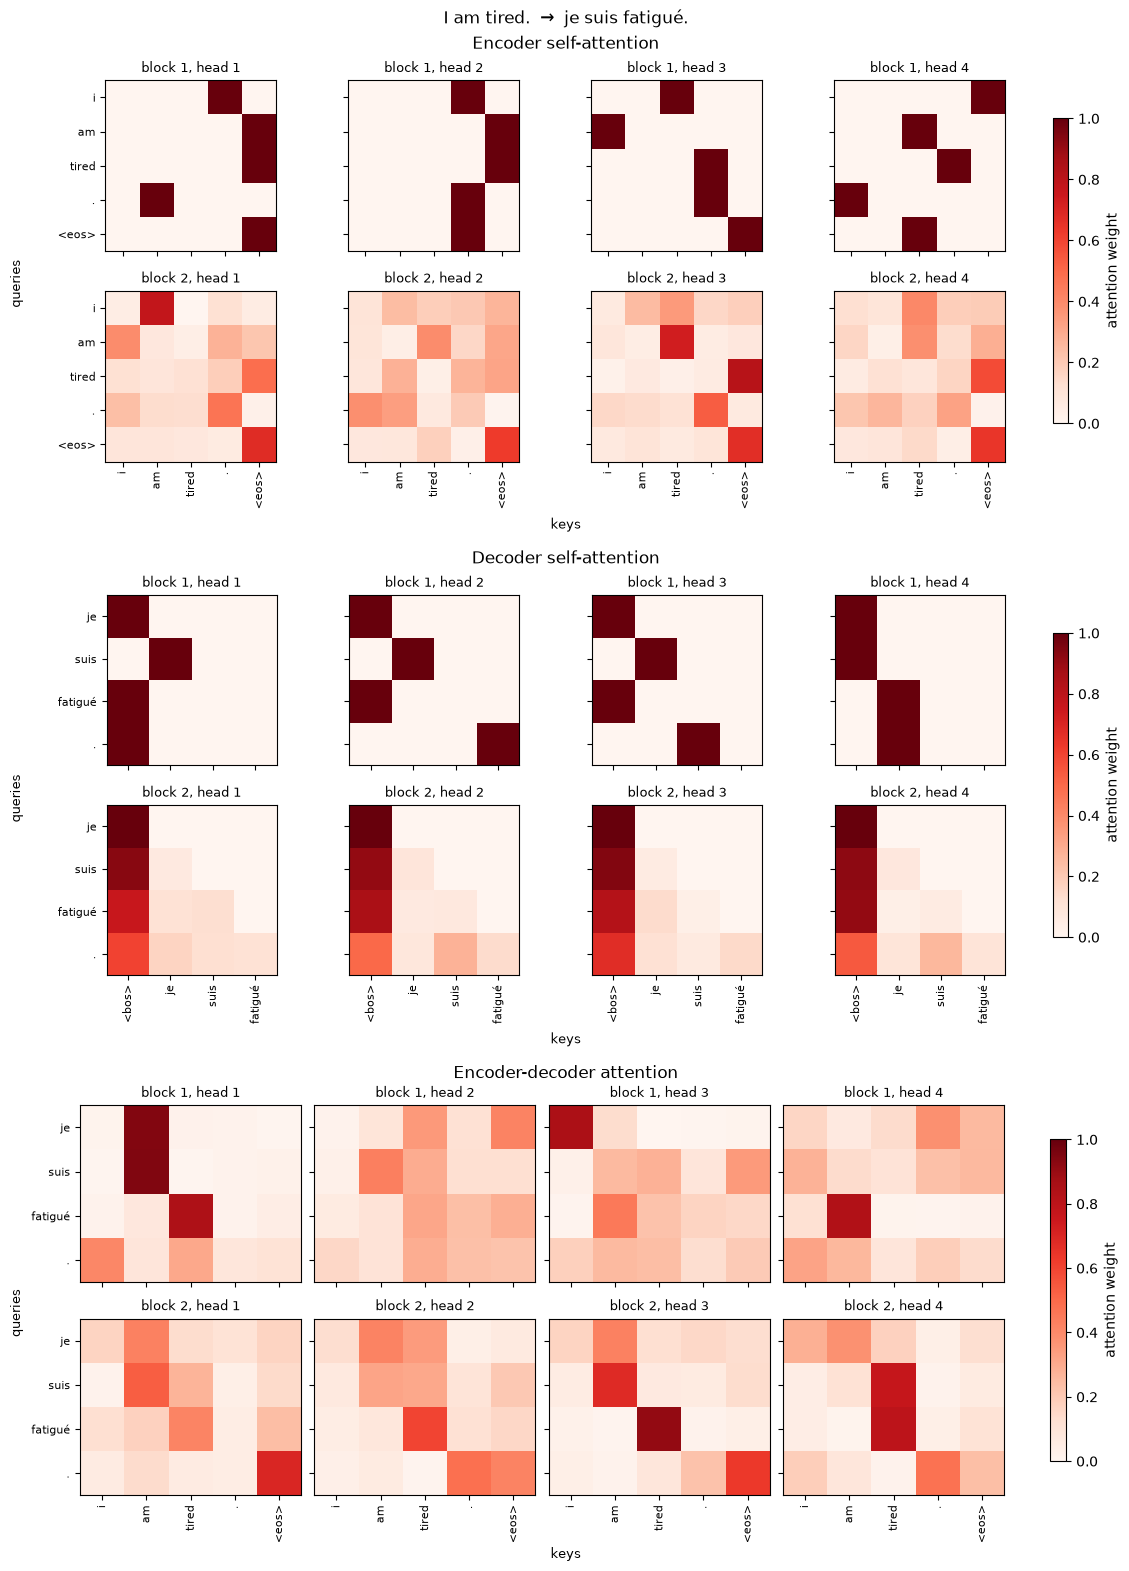

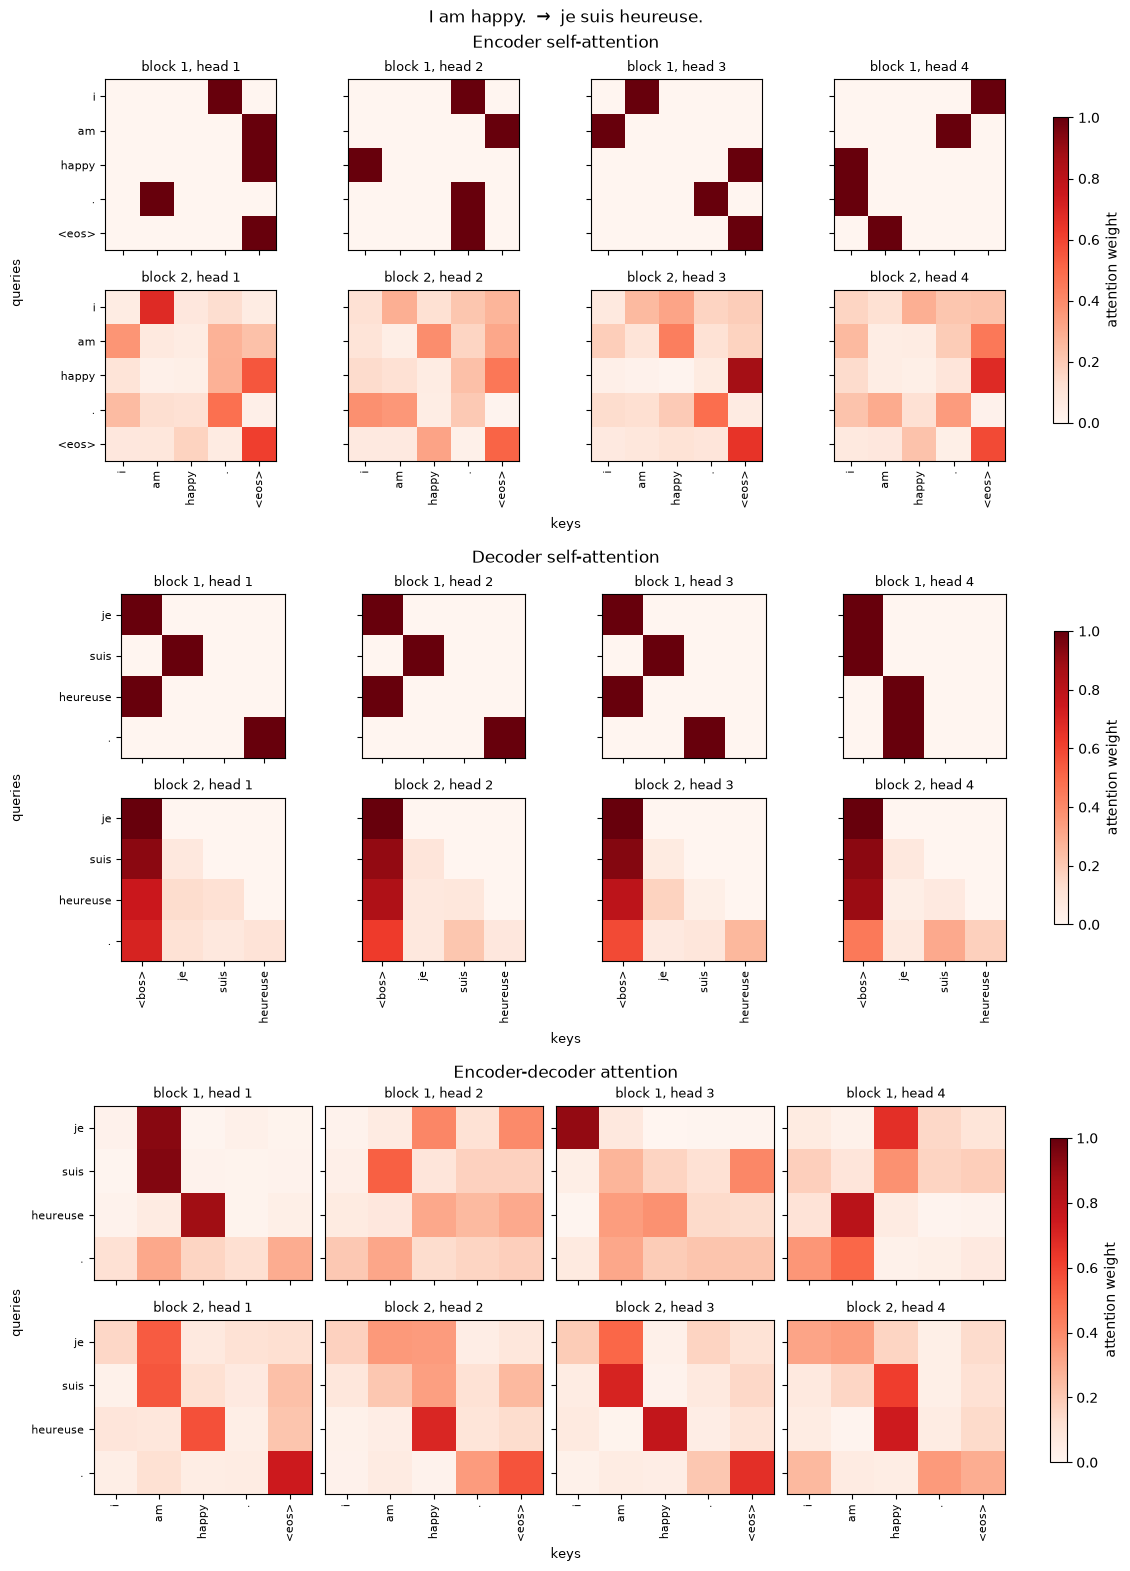

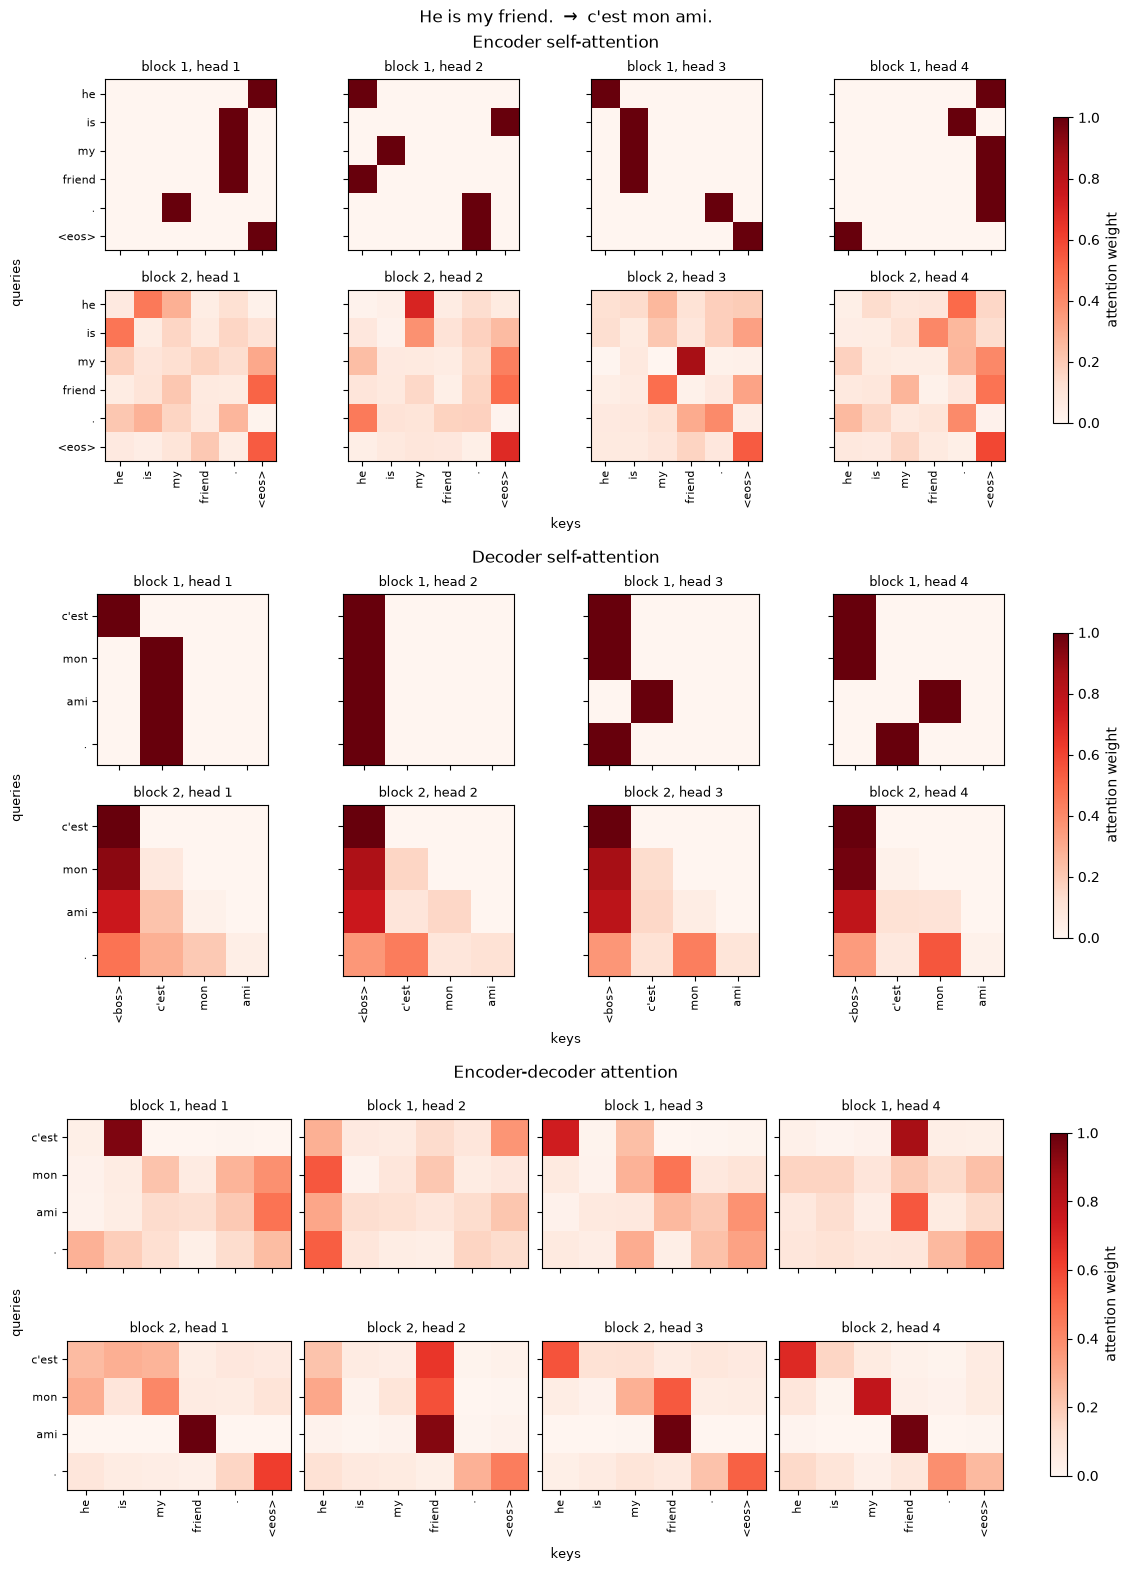

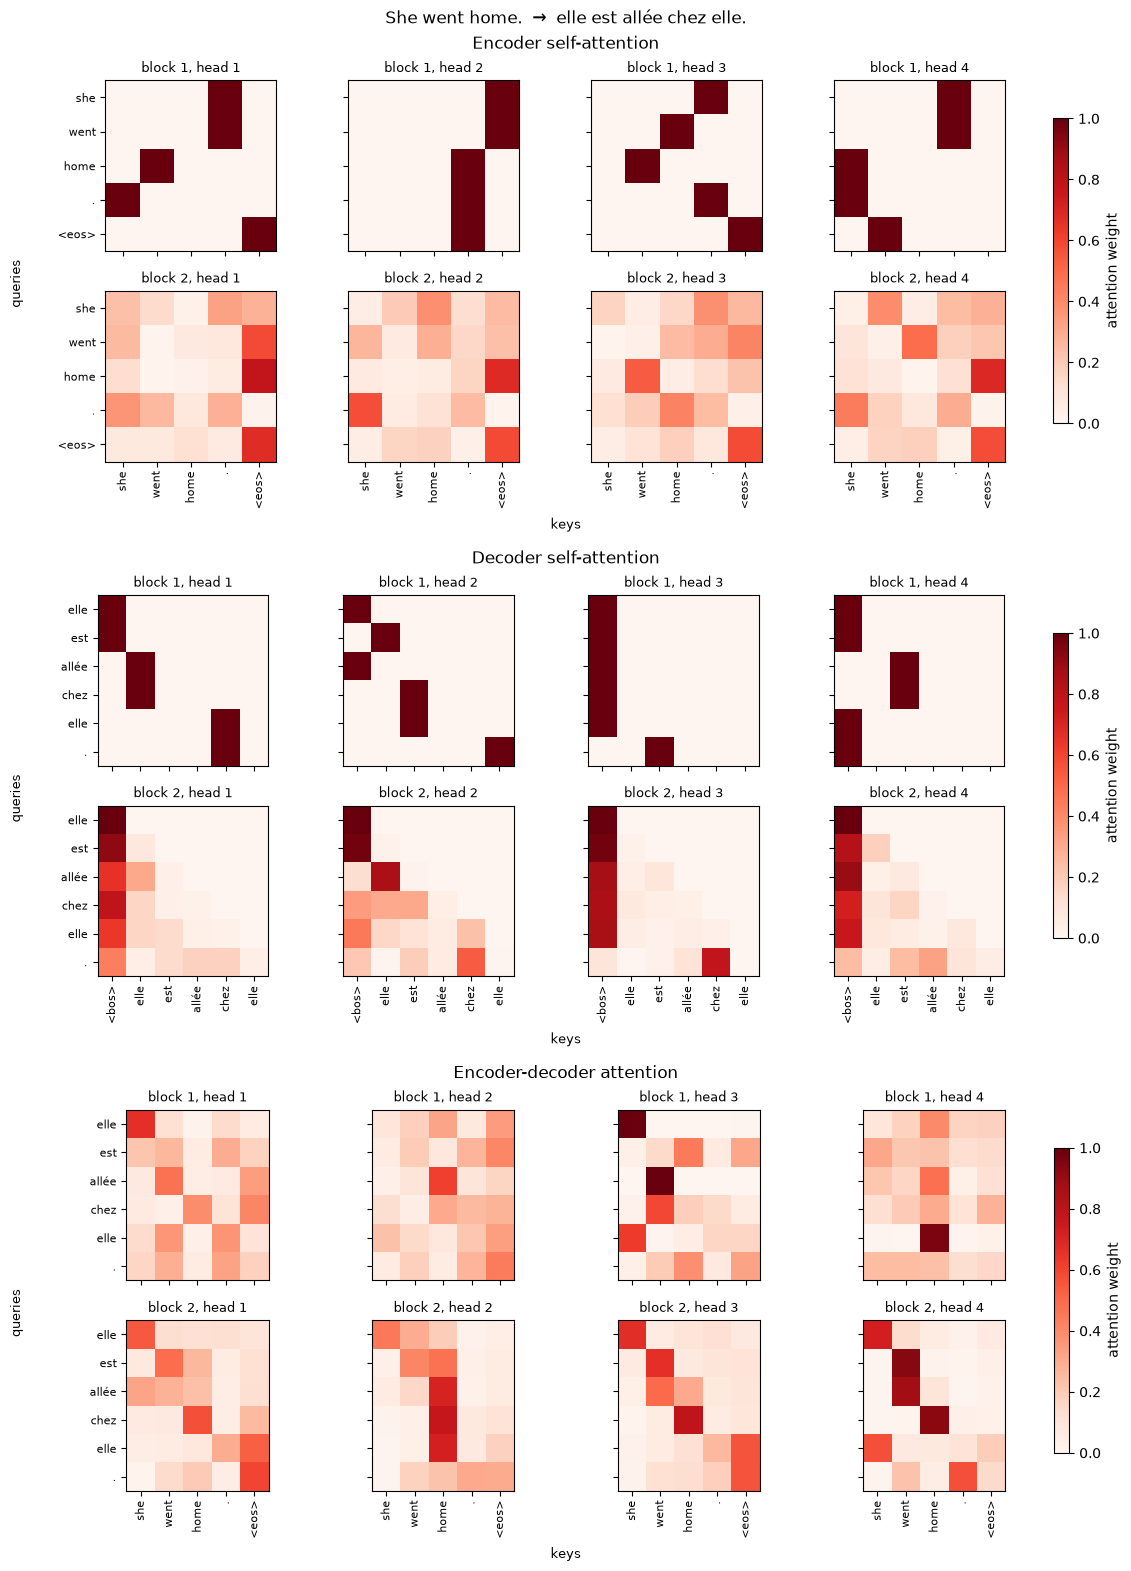

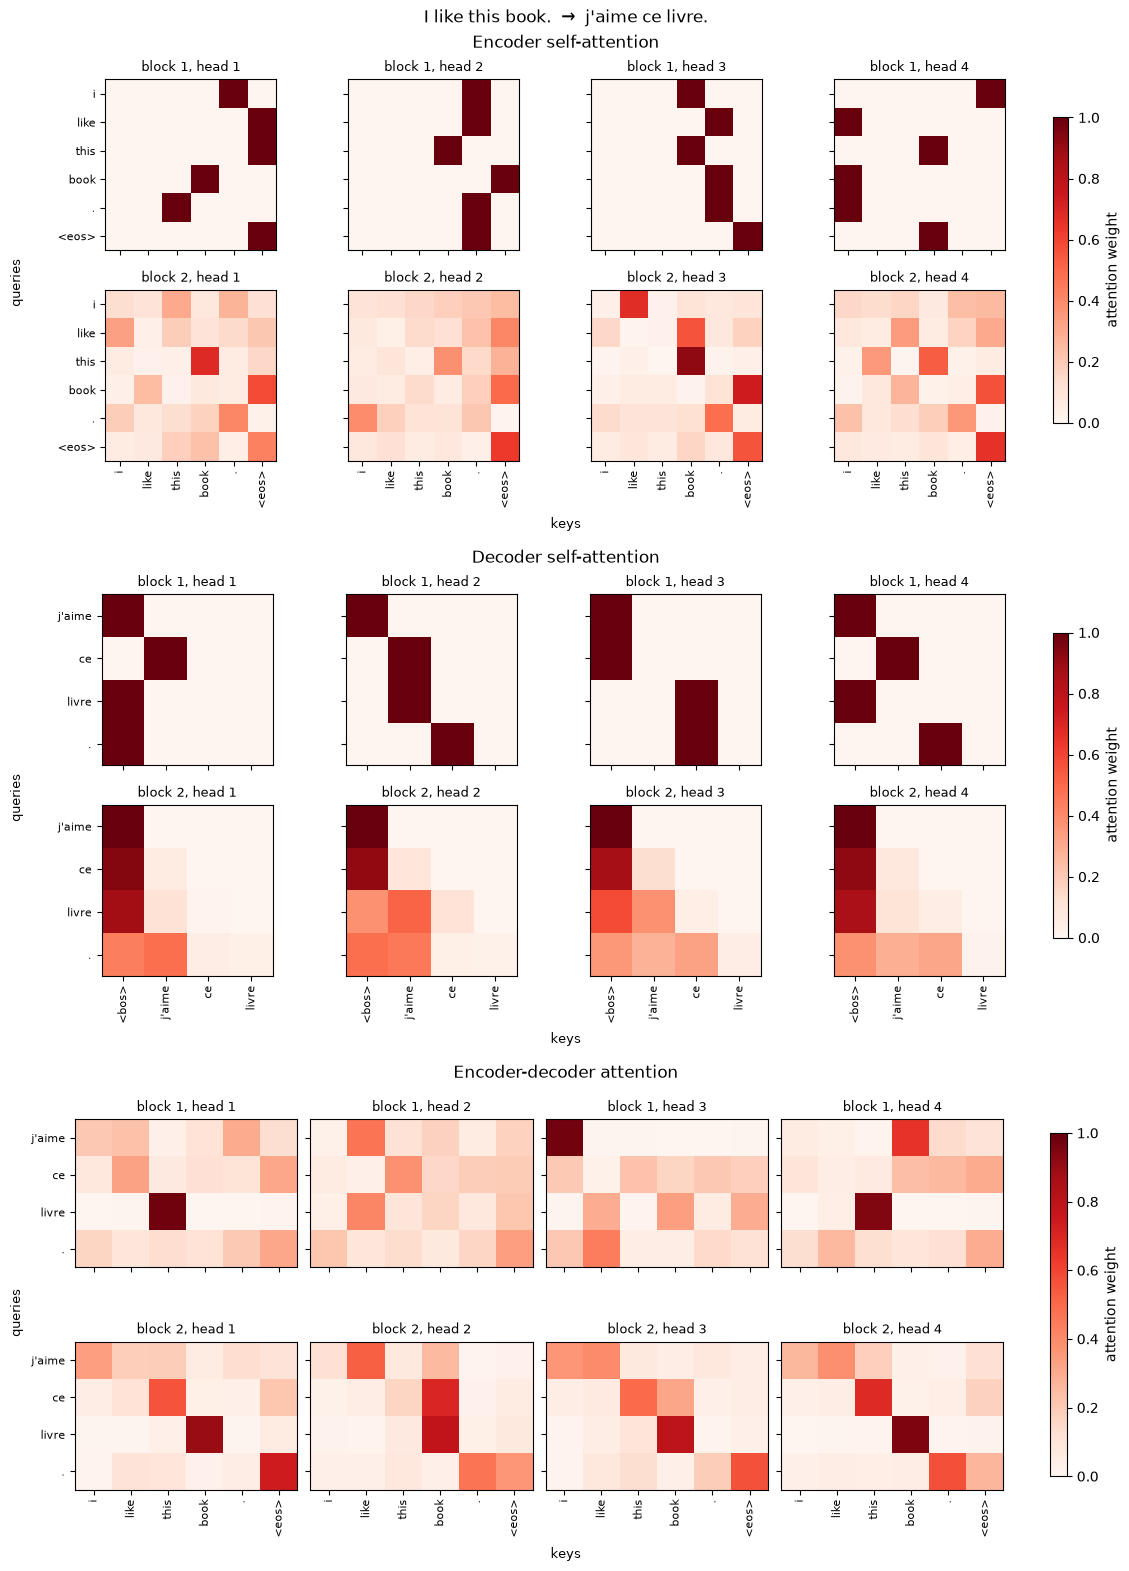

In [12]:
@torch.inference_mode()
def attention_weights_for(source_words, target_words):
    """Runs the model over a finished translation and returns its attention weights.

    The decoder gets the translated tokens one at a time, so every step sees the
    same cache as during decoding and the weights match the ones that produced
    the translation.

    Args:
        source_words: Source tokens including `<eos>`, as returned by `translate`.
        target_words: Translated tokens without `<bos>` and `<eos>`.

    Returns:
        Encoder self-attention (num_blocks, num_heads, num_source, num_source),
        decoder self-attention (num_blocks, num_heads, num_target, num_target) and
        encoder-decoder attention (num_blocks, num_heads, num_target, num_source).
    """
    model.eval()
    source = torch.tensor([mt_data.src_vocab[source_words]], device=DEVICE)
    source_lengths = torch.tensor([len(source_words)], device=DEVICE)
    state = decoder.init_state(encoder(source, source_lengths), source_lengths)
    # Batch size is 1, so each block's (batch * heads, ...) weights are (heads, ...).
    encoder_attention = torch.stack(encoder.attention_weights)

    decoder_inputs = [mt_data.tgt_vocab['<bos>'], *mt_data.tgt_vocab[target_words[:-1]]]
    num_target = len(decoder_inputs)
    self_steps, cross_steps = [], []
    for index in decoder_inputs:
        _, state = decoder(torch.tensor([[index]], device=DEVICE), state)
        self_weights, cross_weights = decoder.attention_weights
        # Step t attends to t + 1 decoder tokens; pad the rest of the row with zeros.
        step_self = torch.stack(self_weights)[:, :, 0]
        self_steps.append(nn.functional.pad(step_self, (0, num_target - step_self.shape[-1])))
        cross_steps.append(torch.stack(cross_weights)[:, :, 0])
    return (
        encoder_attention.cpu(),
        torch.stack(self_steps, dim=2).cpu(),
        torch.stack(cross_steps, dim=2).cpu(),
    )


def show_attention(sentence, translation, source_words, target_words):
    """Plots every block and head of all three attention types for one translation.

    Args:
        sentence: English input sentence.
        translation: French translation shown in the title.
        source_words: Source tokens including `<eos>`.
        target_words: Translated tokens without `<bos>` and `<eos>`.
    """
    if not target_words:
        print(f'No attention to show for {sentence!r}: the translation is empty.')
        return
    encoder_attention, decoder_attention, cross_attention = attention_weights_for(
        source_words, target_words
    )
    decoder_inputs = ['<bos>', *target_words[:-1]]
    panels = [
        ('Encoder self-attention', encoder_attention, source_words, source_words),
        ('Decoder self-attention', decoder_attention, target_words, decoder_inputs),
        ('Encoder-decoder attention', cross_attention, target_words, source_words),
    ]
    fig = plt.figure(
        figsize=(2.8 * NUM_HEADS, 2.6 * NUM_BLOCKS * len(panels)), layout='constrained'
    )
    fig.suptitle(f'{sentence}  →  {translation}', fontsize=12)
    for subfig, (title, weights, queries, keys) in zip(
        fig.subfigures(len(panels), 1), panels
    ):
        subfig.suptitle(title)
        axes = subfig.subplots(
            NUM_BLOCKS, NUM_HEADS, sharex=True, sharey=True, squeeze=False
        )
        for block in range(NUM_BLOCKS):
            for head in range(NUM_HEADS):
                ax = axes[block, head]
                image = ax.imshow(
                    weights[block, head].numpy(), cmap='Reds', vmin=0, vmax=1
                )
                ax.set_title(f'block {block + 1}, head {head + 1}', fontsize=9)
                ax.tick_params(axis='x', labelrotation=90, labelsize=8)
                ax.tick_params(axis='y', labelsize=8)
        # Axes are shared, so these ticks apply to every heatmap in the grid.
        axes[0, 0].set_xticks(range(len(keys)), keys)
        axes[0, 0].set_yticks(range(len(queries)), queries)
        subfig.supxlabel('keys', fontsize=9)
        subfig.supylabel('queries', fontsize=9)
        subfig.colorbar(image, ax=axes, shrink=0.8, label='attention weight')
    plt.show()


for result in translations[0:5]:
    show_attention(*result)

## BLEU-4 evaluation

Evaluate greedy translations against the validation references with corpus BLEU-4 and add-one smoothing.

In [9]:
def corpus_bleu(references, candidates, max_n: int = 4) -> float:
    matches = [0] * max_n
    totals = [0] * max_n
    reference_length = candidate_length = 0

    for reference, candidate in zip(references, candidates):
        reference_length += len(reference)
        candidate_length += len(candidate)
        for n in range(1, max_n + 1):
            reference_ngrams = collections.Counter(
                tuple(reference[i:i + n]) for i in range(len(reference) - n + 1)
            )
            candidate_ngrams = collections.Counter(
                tuple(candidate[i:i + n]) for i in range(len(candidate) - n + 1)
            )
            matches[n - 1] += sum((reference_ngrams & candidate_ngrams).values())
            totals[n - 1] += sum(candidate_ngrams.values())

    if candidate_length == 0:
        return 0.0
    precisions = [
        (matches[i] + 1) / (totals[i] + 1)
        for i in range(max_n)
        if totals[i] > 0
    ]
    brevity_penalty = math.exp(min(0, 1 - reference_length / candidate_length))
    return 100 * brevity_penalty * math.exp(
        sum(math.log(precision) for precision in precisions) / len(precisions)
    )

@torch.inference_mode()
def evaluate_bleu(loader) -> float:
    model.eval()
    bos_index = mt_data.tgt_vocab['<bos>']
    eos_index = mt_data.tgt_vocab['<eos>']
    special_indices = {bos_index, eos_index, PAD_INDEX}
    references, candidates = [], []

    for source, source_lengths, target, _ in loader:
        source = source.to(DEVICE)
        source_lengths = source_lengths.to(DEVICE)
        state = decoder.init_state(encoder(source, source_lengths), source_lengths)
        decoder_input = torch.full(
            (source.shape[0], 1), bos_index, dtype=torch.long, device=DEVICE
        )
        batch_candidates = [[] for _ in range(source.shape[0])]
        finished = [False] * source.shape[0]

        for _ in range(MAX_STEPS):
            logits, state = decoder(decoder_input, state)
            next_indices = logits[:, -1].argmax(dim=-1)
            for i, index in enumerate(next_indices.tolist()):
                if not finished[i]:
                    if index == eos_index:
                        finished[i] = True
                    elif index not in special_indices:
                        batch_candidates[i].append(index)
            if all(finished):
                break
            decoder_input = next_indices.unsqueeze(1)

        candidates.extend(batch_candidates)
        for row in target.tolist():
            reference = []
            for index in row:
                if index == eos_index:
                    break
                if index not in special_indices:
                    reference.append(index)
            references.append(reference)

    return corpus_bleu(references, candidates)

bleu_score = evaluate_bleu(validation_loader)
logger.info(f'validation BLEU-4: {bleu_score:.2f}')

08:42:51 | validation BLEU-4: 40.71
